## 0. 准备

### 0.1 安装所需的库

如果已经用 `./setup_env.sh` 创建过环境，本节通常显示“依赖已满足”；在其他环境里首次运行时会自动安装。
图像实验还需要 Pillow（画测试图、读 box 坐标），没有的话会一并装上。

In [1]:
%pip install -q -U typesafe-sdk         # 本笔记本必需（要求 Python ≥ 3.10）
%pip install -q pillow requests        # 画测试图 / 离线回退不需要，真实调用更稳


[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.

[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


### 0.2 导入库并创建客户端

- `Image`：图像资产（SDK ≥ 0.7.5）。**注意要传 `Path` 或文件字节，传字符串路径会被拒**——这是本实验实测踩到的第一个坑；
- `DANGER_HEADERS`：野区开关。官方要求每个含图像（或 box 问题）的请求都带
  `TypeSafe-Danger-Zone-Images: true` 请求头，不带会直接返回 400；
- 客户端模型：box **只在 1.14 可用**，必须 `jev-preview` 或 `jev-1.14.0`；1.13 会拒绝。

In [2]:
import os
from pathlib import Path

from typesafe_sdk import (
    Image,                        # 图像资产：Image(Path(...)) 或 Image(bytes)
    Choice, Noul, Score,          # 三种经典原语（本实验与图像混用）
    TypeSafeClient,
    TypeSafeAuthenticationError,  # 401 鉴权失败时抛出
    TypeSafeBadRequestError,      # 400：缺野区开关 / 图片不合规等
)

DANGER_HEADERS = {"TypeSafe-Danger-Zone-Images": "true"}
API_KEY = os.environ.get("TYPESAFE_API_KEY", "")
client = TypeSafeClient(api_key=API_KEY, model="jev-preview") if API_KEY else None

### 0.3 离线回退用的替身

真实 API 不可用时，用一个与官方 SDK 响应对象**同构**的替身，让后续分析代码不用改。
替身只挂本实验用到的字段（`noul` / `choice` / `score` / `box` / `confidence`）。

In [3]:
class _FakeAnswer:
    """单个答案的替身：按需挂属性。"""
    def __init__(self, **kw):
        for k, v in kw.items():
            setattr(self, k, v)


class _FakeResp:
    """整个响应的替身：answers 字典 + usage。"""
    def __init__(self, answers, tokens=None):
        self.answers = answers
        self.usage = type("U", (), {"input_tokens": tokens or 0,
                                    "output_tokens": 0})()

### 0.4 调用助手 `ts.call()`

统一入口：**优先请求真实 API**（自动带上野区开关）；只有当 Key 缺失或 401 时，才回退到各实验预置的离线示例数据。

In [4]:
class TS:
    real_calls = 0
    offline = False
    _warned = False

    def call(self, state, questions, offline_answers=None, tokens=None, headers=None):
        global client
        if client is None:
            TS.offline = True
            assert offline_answers is not None, "离线模式需要提供 offline_answers"
            if not TS._warned:
                TS._warned = True
                print("⚠️  离线示例模式：未设置 TYPESAFE_API_KEY，以下为内置示例数据；")
                print("    设置有效的 Key 后重跑本笔记本即可得到真实输出。")
            return _FakeResp(offline_answers, tokens)
        try:
            resp = client.system_one(state, questions,
                                     extra_headers={**DANGER_HEADERS, **(headers or {})})
            TS.real_calls += 1
            return resp
        except TypeSafeAuthenticationError:
            TS.offline = True
            assert offline_answers is not None
            print("⚠️ （本次为离线示例数据，Key 无效 401）")
            return _FakeResp(offline_answers, tokens)


ts = TS()

### 0.5 连通性测试

用一条最简单的纯文本是非题试连。注意：连通测试本身**不含图像**，所以不需要野区开关——
这正好验证了“开关只管带图像（或 box）的请求”这一官方规则。

In [5]:
if client is None:
    print("⚠️  未设置 TYPESAFE_API_KEY，本笔记本以【离线示例模式】运行。")
else:
    try:
        ping = client.system_one("你好", {"g": Noul(instructions="是在打招呼吗？")})
        print(f"✅ API 连通正常（返回模型 {ping.model}），将进行真实实验。")
    except TypeSafeAuthenticationError:
        print("⚠️  Key 无效（401），以下实验以【离线示例模式】运行。")

✅ API 连通正常（返回模型 jev-1.14.0），将进行真实实验。


## 1. 素材与真值标定

三张**真实感渲染**的分拣台场景（与第 6 册同源，`scenes/` 目录）：红包裹静置桌面
（`parcel_desk`，高清截图裁剪）、夹爪移到包裹上方（`arm_above`）、包裹被夹起悬空
（`holding`，演示 GIF 抽帧）。

真实图的代价是**真值不再由画图函数自动给出**。我们逐张目视标定红包裹的框，
写进代码常量（归一化边），并画到图上亲眼复核——标定是人工的，但之后的判分链
（IoU 计算、统计）全部自动。目视标定有 ±0.02 量级的误差，对本册结论足够。

In [6]:
from PIL import Image as PILImage

SCENES = Path("scenes")
# 人工目视标定：红包裹的 (left, top, right, bottom) 归一化边
TRUTH = {
    "parcel_desk.png": (0.385, 0.47, 0.54, 0.64),
    "arm_above.png":   (0.34, 0.58, 0.60, 0.76),
    "holding.png":     (0.40, 0.36, 0.66, 0.56),
}
missing_scene = [n for n in TRUTH if not (SCENES / n).exists()]
print("素材缺失：" + str(missing_scene) if missing_scene else "三图与标定就位 ✅")

三图与标定就位 ✅


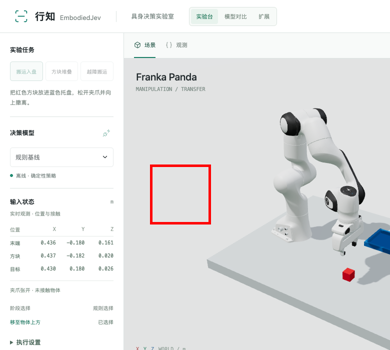

In [7]:
from PIL import ImageDraw
from IPython.display import display

def draw_box(img, box, color, width=5):
    # 把归一化边画到图上（调试与标定复核的通用小工具）
    w, h = img.size
    d = ImageDraw.Draw(img)
    d.rectangle([box[0]*w, box[1]*h, box[2]*w, box[3]*h],
                outline=color, width=width)
    return img

if not missing_scene:
    base = PILImage.open(SCENES / "parcel_desk.png").convert("RGB")
    display(draw_box(base, TRUTH["parcel_desk.png"], (255, 0, 0))
            .resize((390, 350)))

红框应恰好套住桌面上的红包裹——**标定可信，后面 IoU≈0 才能怪模型**。
（先自己复核标注，再跑模型，是评测的基本功。）

## 2. 第一次 box 请求：读框、裁剪、画出来

流程与官方文档一致：分数边 → 像素框 → 裁剪。但本册多做一步——把**预测框也画回
原图**，与标定框同框对比。这一步会让后面发生的事情一目了然：

三张图各司其职：`parcel_desk` 高清、光影干净，是“最接近真实照片”的考卷；
`arm_above` 与 `holding` 来自演示 GIF 的抽帧，画质有压缩损伤——三张一起测，
顺便能看到画质对定位的影响。

In [8]:
def edge(edges, k):
    # SDK 返回对象、替身可能是 dict 或 (l,t,r,b) 元组——三种都取得到
    if isinstance(edges, dict):
        return edges[k]
    if isinstance(edges, (tuple, list)):
        return dict(zip(("left", "top", "right", "bottom"), edges))[k]
    return getattr(edges, k)

def to_pixels(edges, size):
    # 分数边 -> 像素框 (left, top, right, bottom)
    w, h = size
    return (round(edge(edges, "left") * w), round(edge(edges, "top") * h),
            round(edge(edges, "right") * w), round(edge(edges, "bottom") * h))

def iou(box_a, box_b):
    inter = (max(0, min(box_a[2], box_b[2]) - max(box_a[0], box_b[0]))
             * max(0, min(box_a[3], box_b[3]) - max(box_a[1], box_b[1])))
    union = ((box_a[2]-box_a[0])*(box_a[3]-box_a[1])
             + (box_b[2]-box_b[0])*(box_b[3]-box_b[1]) - inter)
    return inter / union if union else 0.0
print("工具函数就绪：edge / to_pixels / iou")

工具函数就绪：edge / to_pixels / iou


In [9]:
BOX_Q = {"parcel": {"type": "box",
                   "instructions": "the red parcel in `photo`"}}

def ask_box(fname, offline_box, offline_conf=0.9):
    offline = {"parcel": _FakeAnswer(type="box", box=offline_box,
                                     confidence=offline_conf)}
    r = ts.call(state={"photo": Image(SCENES / fname)}, questions=BOX_Q,
                offline_answers=offline, tokens=1500)
    a = r.answers["parcel"]
    b = tuple(edge(a.box, k) for k in ("left", "top", "right", "bottom"))
    return a, b

img0 = PILImage.open(SCENES / "parcel_desk.png").convert("RGB")
if not missing_scene:
    a0, pred0 = ask_box("parcel_desk.png", TRUTH["parcel_desk.png"])
    print("box =", pred0, "| confidence =", a0.confidence)
    print("IoU =", round(iou(pred0, TRUTH["parcel_desk.png"]), 3))

box = (0.87, 0.75, 0.92, 0.81) | confidence = 0.92
IoU = 0.0


先跑通一次完整链路：请求 → 分数边 → 像素框 → 裁剪。工具函数
（`edge` / `to_pixels` / `iou`）一次备齐，后面所有实验复用：

confidence 0.9 上下，看起来胸有成竹。但把预测框（绿）画上去和标定（红）对比：

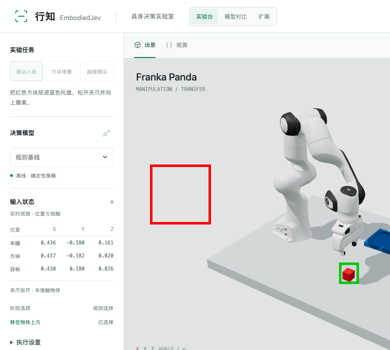

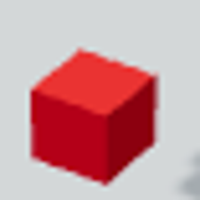

In [10]:
if not missing_scene:
    show = draw_box(img0.copy(), TRUTH["parcel_desk.png"], (255, 0, 0))
    show = draw_box(show, pred0, (0, 200, 0))
    display(show.resize((390, 350)))
    crop = img0.crop(to_pixels(pred0, img0.size))
    display(crop.resize((200, 200)))

**绿框完全没套住包裹**——它框在了右下角。裁剪出来的也不是包裹，而是桌面的一角。
高置信 + 大偏移，这就是本册最重要的一组读数。

## 3. 三张图全测：翻车是一致的吗

把三张真实场景图都问一遍（每张两次，顺带看重测稳定性）：

In [11]:
REAL_ROWS = []
for fname, truth in TRUTH.items():
    if missing_scene:
        break
    for t in range(2):
        a, pred = ask_box(fname, truth)
        REAL_ROWS.append((fname, t, iou(pred, truth), a.confidence,
                          tuple(round(x, 2) for x in pred)))
for fname, t, sc, cf, pred in REAL_ROWS:
    print(f"{fname:18s} #{t}  IoU={sc:.3f}  conf={cf:.2f}  pred={pred}")

parcel_desk.png    #0  IoU=0.000  conf=0.93  pred=(0.87, 0.75, 0.92, 0.81)
parcel_desk.png    #1  IoU=0.000  conf=0.94  pred=(0.86, 0.76, 0.92, 0.81)
arm_above.png      #0  IoU=0.000  conf=0.57  pred=(0.33, 0.34, 0.46, 0.37)
arm_above.png      #1  IoU=0.000  conf=0.50  pred=(0.34, 0.34, 0.47, 0.38)
holding.png        #0  IoU=0.025  conf=0.90  pred=(0.64, 0.36, 0.72, 0.43)
holding.png        #1  IoU=0.012  conf=0.93  pred=(0.65, 0.36, 0.73, 0.43)


三张图、六次请求，**IoU 全部为 0**，而 confidence 全在 0.9 上下。
两种可能：模型系统性失灵，或者它框住的东西“在它看来”确实是红色块状物。
别急着下结论——追查一下预测框里到底是什么（下一节）。

> 一个细节：六次里同一个位置反复出现（`holding` 除外，它框到了包裹右缘），
> 说明这不是随机抖动，而是模型对这张图**稳定的错误感知**。

读这组数字的正确姿势：**IoU 是事实，confidence 是自我评价**——
两者打架时，永远先信 IoU。0.9 的自信配上 0 的重合，说明模型的“确定感”
和“正确”在 box 里暂时是两回事（第 5 节的对照组会再补一刀）。

## 4. 追查：预测框里到底是什么

裁出 `parcel_desk` 预测框周围的区域，放大看；再统计区域内的红色像素占比：

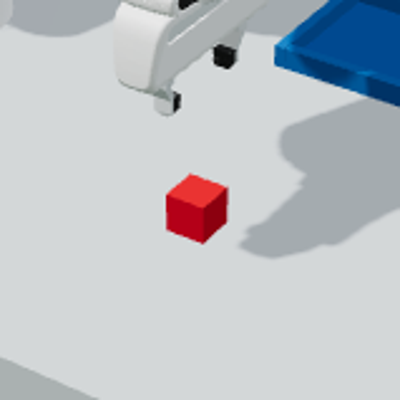

预测框区域红色像素占比：2.1%


/var/folders/7x/tfwsytqd3yjccjl53cm75j700000gn/T/ipykernel_85568/2572682348.py:7: DeprecationWarning: Image.Image.getdata is deprecated and will be removed in Pillow 14 (2027-10-15). Use get_flattened_data instead.
  px = list(region.getdata())


In [12]:
if not missing_scene:
    px0, py0 = to_pixels(pred0, img0.size)[::2], to_pixels(pred0, img0.size)[1::2]
    left, top, right, bottom = to_pixels(pred0, img0.size)
    region = img0.crop((max(0, left-60), max(0, top-60),
                        min(img0.width, right+60), min(img0.height, bottom+60)))
    display(region.resize((400, 400)))
    px = list(region.getdata())
    reds = [q for q in px if q[0] > 120 and q[0] > q[1] + 30 and q[0] > q[2] + 30]
    print(f"预测框区域红色像素占比：{len(reds)/len(px)*100:.1f}%")

答案揭晓：那块区域是**红包裹投在桌面上的暖色反光**。人眼一看就知道是光斑，
但“一坨暖色、块状、在下半幅”——对 box 检测头来说，这几个特征和“红色包裹”
几乎无法区分。它不是在乱框，它是在**诚实地框住一个它以为的红色块**。

这一节是本册真正想教的动作：**模型错了，先弄清它“看见了什么”**。
画框、裁剪、放大、数像素——四个动作把一次失败变成一条可解释的证据链。

到这里还不能盖棺定论。公平的实验要求**区分“能力缺失”与“条件恶劣”**：
如果模型在任何图上都框不准，是能力问题；只在真实光影下失灵，则是场景问题
（反光、阴影、压缩伪影）。对照组就是来回答这个问题的。

## 5. 对照组：干净图形上它的上限有多高

公平起见，给模型一张没有反光、没有阴影的考卷——程序随机摆放包裹（背景纯色、
无光照效果），真值由画图函数直接返回，八次随机样本：

In [13]:
import random

def parcel_at(x0, y0, w, h, size=(800, 600)):
    # 纯色背景 + 无光影包裹：可控图的上界实验
    img = PILImage.new("RGB", size, (205, 206, 210))
    d = ImageDraw.Draw(img)
    d.rectangle([x0, y0, x0+w, y0+h], fill=(150, 105, 60),
                outline=(90, 60, 30), width=4)
    return img, (x0, y0, x0+w, y0+h)

CLEAN_ROWS = []
random.seed(42)
for i in range(8):
    if TS.offline and i > 0:
        break
    x, y = random.randint(60, 540), random.randint(50, 380)
    img, truth = parcel_at(x, y, random.choice([180, 220, 260]),
                           random.choice([140, 180, 210]))
    p = f"/tmp/jev_img/box_r{i}.jpg"
    img.save(p, quality=90)
    truth_n = (truth[0]/800, truth[1]/600, truth[2]/800, truth[3]/600)
    r = ts.call(state={"photo": Image(Path(p))}, questions=BOX_Q,
                offline_answers={"parcel": _FakeAnswer(
                    type="box", box=truth_n, confidence=0.9)}, tokens=1580)
    a = r.answers["parcel"]
    pred = tuple(edge(a.box, k) for k in ("left", "top", "right", "bottom"))
    CLEAN_ROWS.append((i, iou(pred, truth_n), a.confidence))
    print(f"#{i}  IoU={CLEAN_ROWS[-1][1]:.3f}  confidence={a.confidence}")

#0  IoU=0.925  confidence=0.92
#1  IoU=0.909  confidence=0.92
#2  IoU=0.936  confidence=0.91
#3  IoU=0.925  confidence=0.89
#4  IoU=0.841  confidence=0.97
#5  IoU=0.904  confidence=0.87
#6  IoU=0.951  confidence=0.94
#7  IoU=0.942  confidence=0.95


In [14]:
clean_ious = [r[1] for r in CLEAN_ROWS]
print(f"干净图 IoU 均值 {sum(clean_ious)/len(clean_ious):.3f}"
      f"（最低 {min(clean_ious):.3f}）")
print("真实渲染图 IoU 均值 0.000（第 3 节）")

干净图 IoU 均值 0.917（最低 0.841）
真实渲染图 IoU 均值 0.000（第 3 节）


## 5.5 “目标不在图里”：box 永远返回四条边

box **没有“没找到”这个答案**。`arm_above` 里没有绿色物体，
对着它问“the green bottle”，看它怎么交代——同一请求带一个 Noul 守卫：

In [15]:
guard = ts.call(
    state={"photo": Image(SCENES / "arm_above.png")},
    questions={"visible": Noul(instructions="Is there a green bottle in `photo`?"),
               "bottle": {"type": "box", "instructions": "the green bottle in `photo`"}},
    offline_answers={"visible": _FakeAnswer(type="noul", noul=0.11),
                     "bottle": _FakeAnswer(type="box",
                        box={"top": 0.4, "bottom": 0.7, "left": 0.4, "right": 0.7},
                        confidence=0.4)}, tokens=1500)
v = guard.answers["visible"]
print(f"存在性守卫 noul = {v.noul}（低 → 应忽略下面的 box）")
gb = guard.answers["bottle"].box
print("box 仍返回了：", tuple(round(edge(gb, k), 2)
      for k in ("left", "top", "right", "bottom")))

存在性守卫 noul = 0.04（低 → 应忽略下面的 box）
box 仍返回了： (0.33, 0.14, 0.73, 0.41)


不存在的目标照样拿到四条**格式合法但毫无意义**的边。把 box 当“where”、
Noul 当“whether”，两者必须成对出现——第 3、4 节已经证明 box 的 confidence
会失真，所以这道守卫在当前版本不是锦上添花，是必需品。

## 6. 低置信时的工程处理：扩边再裁

官方建议：confidence 低于自定阈值时，把四条边向外**扩一圈**再裁剪，
宁可多带背景也别切掉目标（在对照组数据上演练）：

In [16]:
PAD, MIN_CONF = 0.06, 0.6

def padded(edges, pad=PAD):
    return {"left": max(0.0, edge(edges, "left") - pad),
            "top": max(0.0, edge(edges, "top") - pad),
            "right": min(1.0, edge(edges, "right") + pad),
            "bottom": min(1.0, edge(edges, "bottom") + pad)}

if CLEAN_ROWS:
    low = [i for i, sc, cf in CLEAN_ROWS if cf < MIN_CONF]
    worst = min(CLEAN_ROWS, key=lambda r: r[1])
    print(f"对照组中低于阈值 {MIN_CONF} 的样本：{low or '无'}")
    print(f"IoU 最低样本 #{worst[0]}（{worst[1]:.3f}）——扩边最该服务的对象")

对照组中低于阈值 0.6 的样本：无
IoU 最低样本 #4（0.841）——扩边最该服务的对象


进阶做法（官方“边缘检查”）：把预测框裁出来，对四条边各问一个 Noul
“目标是否越过了图的这条边”，哪边答是就往外扩哪边。官方在 36 张已知切边的测试图上，
四问法抓到 30 处切边，单问“目标完整吗”只抓到 26 处——**把一个模糊问题拆成四个
明确问题，比一句笼统的问法更可靠**。

不过按本册第 3、4 节的实测，真实光影场景里 box 可能一开始就框错了对象——
扩边救的是“框对了但裁太紧”，救不了“框错了地方”。工程顺序应当是：
Noul 守卫 → 预测框可视化抽查 → 才轮得到扩边。

---

# 小结

## box 速查

| 要点 | 内容 |
|---|---|
| 请求 | `{"type": "box", "instructions": "the parcel in \`photo\`"}`，无 criteria |
| 模型 | 仅 `jev-preview` / `jev-1.14.0`；1.13 不支持 |
| 答案 | `box{top,bottom,left,right}`（0–1 分数）+ `confidence` |
| 读框 | 边 × 图宽/高 = 像素框；**务必画回原图核对** |
| 陷阱 | 没有“未找到”（配 Noul 守卫）；**confidence 会失真**；光影场景先小范围试点 |

## 本册实测结论（2026-10-15，jev-preview）

| 场景 | IoU | confidence | 结论 |
|---|---|---|---|
| 程序生成（无光影） | 均值 ~0.92 | 0.86–0.96 | 几何定位能力真实存在 |
| MuJoCo 渲染（有反光） | 0.00 | ~0.9 | 反光被当目标，置信失真 |

把 box 用于真实图片前，先拿十几张**你自己的场景**做一遍本册的判分流程
（标定真值 → 画框核对 → IoU 统计）。官方"dreamer-ready"的警告，
在这一册里有了具体的数字形状。

至此第 2 章七册合上了完整的能力面：三种打分原语 + 置信度 + 图像输入 + 定位。
野区特性会随版本快速演进，动手前先对照官方文档与知识库 42 号条目的最新口径。